# 02 Baseline: do stocks move with their own sector?

**Project:** Do Sectors Describe How Stocks Move?

Before any clustering, a simple baseline with familiar tools (numpy correlation, matplotlib):

1. Correlation between every pair of stocks, shown as a heatmap sorted by sector
2. For each sector: the average correlation **within** the sector vs **with other sectors**

If sectors describe how stocks move, stocks should correlate more with their own sector than with the rest of the market. This gives a first answer to *which sectors move as coherent groups* and a reference point for the clustering results later.

The functions live in `src/baseline.py`. Input is the returns matrix made in notebook 01.

In [1]:
import sys                       # to tell Python where to find our own code

import polars as pl              # data processing

sys.path.append("..")            # the project folder (one level up) holds the src/ package
from src import baseline         # baseline functions

pl.Config.set_tbl_rows(12)       # show at most 12 rows when printing a table

polars.config.Config

## 1. Load the returns matrix and sectors

In [2]:
matrix, sectors = baseline.load_processed()   # stocks x days returns, and sector labels
print("Matrix:", matrix.shape)                # (stocks, ticker column + one column per day)
print("Sectors:", sectors.shape)

Matrix: (495, 502)
Sectors: (495, 4)


## 2. Correlation between every pair of stocks

**Correlation** measures how similarly two stocks move day to day, from -1 (always opposite) through 0 (unrelated) to +1 (always together).

`baseline.correlation_by_sector()`:

1. Adds each stock's sector to its row and sorts by sector, so stocks of the same sector sit next to each other
2. Turns the Polars table into a plain numpy array (only the numbers)
3. Runs `np.corrcoef`, which treats each row (stock) as one variable and returns a stocks x stocks table: cell `[i, j]` is the correlation between stock `i` and stock `j`

In [3]:
corr, labels = baseline.correlation_by_sector(matrix, sectors)
print("Correlation matrix:", corr.shape)          # stocks x stocks
print("Average correlation between two stocks:", round(baseline.average_correlation(corr), 3))
print("Share of negative pairs:", round((corr < 0).mean(), 3))

Correlation matrix: (495, 495)
Average correlation between two stocks: 0.205
Share of negative pairs: 0.093


Most pairs are positively correlated. On a typical day the whole market moves up or down together, so **any** two stocks tend to move together a little. Every comparison below has to beat this market-wide level, not zero.

### Heatmap sorted by sector

Each pixel is one pair of stocks. Blue means they move together, orange means opposite, grey means unrelated. The black lines separate sectors. If a sector is coherent, its square on the diagonal is clearly bluer than the rest of its row.

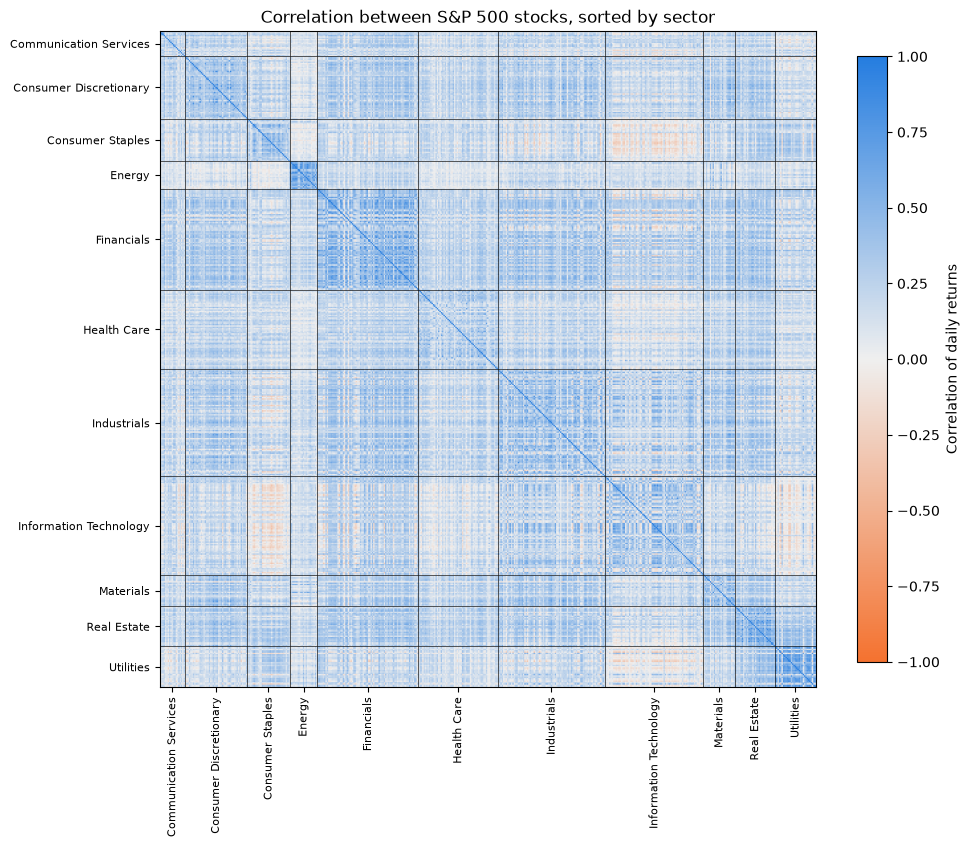

In [4]:
fig = baseline.plot_correlation_heatmap(corr, labels)   # draw the heatmap

**What the heatmap shows:**

- **Energy, Utilities, Real Estate and Financials** have clearly darker blocks on the diagonal: their stocks move together.
- **Health Care, Industrials and Communication Services** barely stand out from their surroundings.
- The light orange patches between **Information Technology and Utilities/Consumer Staples** are pairs that tend to move in opposite directions (growth vs defensive stocks).
- The background is light blue almost everywhere: the market-wide correlation described above.

## 3. Within-sector vs cross-sector correlation

`baseline.sector_summary()` computes for each sector:

- **within**: average correlation between two stocks of that sector (pairs of a stock with itself, always 1.0, are left out)
- **cross**: average correlation between that sector's stocks and all stocks in other sectors
- **gap** = within - cross: how much more a sector's stocks move with each other than with the rest of the market

A large gap means a coherent sector. A small gap means the sector label says little about how its stocks move.

In [5]:
summary = baseline.sector_summary(corr, labels)   # one row per sector, largest gap first
summary

sector,n_stocks,within,cross,gap
str,i64,f64,f64,f64
"""Energy""",21,0.540666,0.129897,0.410768
"""Utilities""",31,0.486638,0.144665,0.341973
"""Real Estate""",30,0.439573,0.234654,0.204919
"""Consumer Staples""",32,0.302872,0.137885,0.164987
"""Financials""",76,0.394422,0.23019,0.164232
"""Information Technology""",74,0.272125,0.14558,0.126546
"""Materials""",24,0.342466,0.22635,0.116116
"""Consumer Discretionary""",47,0.32753,0.220451,0.107079
"""Industrials""",81,0.308856,0.218353,0.090503


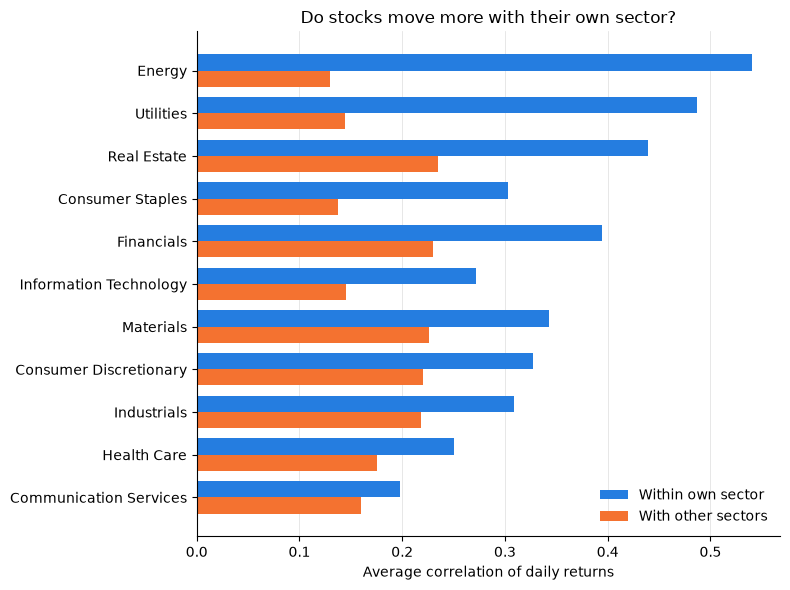

In [6]:
fig = baseline.plot_sector_summary(summary)   # blue = within sector, orange = with other sectors

**What the comparison shows:**

- **Every sector** has a higher within-sector than cross-sector correlation, so sector labels carry some information for all of them.
- **Most coherent: Energy and Utilities.** Their stocks move together far more than with the market (gap around 0.4 and 0.35). Energy stocks share oil and gas prices; utilities share sensitivity to interest rates.
- **Least coherent: Communication Services, Health Care and Industrials.** The gap is under 0.1. These sectors mix very different businesses (e.g. telecoms, media and search engines in Communication Services; pharma, insurers and equipment makers in Health Care).
- **Size is not the reason:** Financials (76 stocks) is fairly coherent, Communication Services (19 stocks) is not.

### Check: what if the duplicate share classes were kept?

Alphabet, Fox and News Corp each have two share classes (e.g. GOOG and GOOGL). The data pipeline keeps only one ticker per company. To see why, we rebuild the matrix **with** the duplicates and compare.

In [7]:
from src import config, data   # settings and pipeline functions

prices = pl.read_parquet(config.RAW_PRICES_PATH)        # raw prices, all tickers
all_sectors = pl.read_parquet(config.RAW_SECTORS_PATH)  # sectors, all tickers

# Same pipeline as notebook 01, but with nothing in the drop list
with_dupes = data.build_returns_pipeline(prices.lazy(), all_sectors.lazy(), drop_tickers=[]).collect()
matrix_dupes = data.fill_nulls_with_zero(data.pivot_returns(with_dupes))
corr_dupes, labels_dupes = baseline.correlation_by_sector(matrix_dupes, all_sectors)
print("Stocks with duplicates:", matrix_dupes.height, "| without:", matrix.height)

Stocks with duplicates: 498 | without: 495


In [8]:
# The two share classes of each company move almost identically
tickers = labels_dupes["ticker"].to_list()   # ticker of each row of corr_dupes, in order
for a, b in [("GOOG", "GOOGL"), ("FOX", "FOXA"), ("NWS", "NWSA")]:
    i, j = tickers.index(a), tickers.index(b)   # row positions of the two share classes
    print(a, b, round(corr_dupes[i, j], 3))

GOOG GOOGL 0.997
FOX FOXA 0.987
NWS NWSA 0.959


In [9]:
summary_dupes = baseline.sector_summary(corr_dupes, labels_dupes)   # sector table with duplicates

# Put both versions side by side for Communication Services (where all three companies are)
compare = summary_dupes.join(summary, on="sector", suffix="_without")
compare.filter(pl.col("sector") == "Communication Services").select(
    "sector", "n_stocks", "n_stocks_without", "within", "within_without", "gap", "gap_without"
)

sector,n_stocks,n_stocks_without,within,within_without,gap,gap_without
str,i64,i64,f64,f64,f64,f64
"""Communication Services""",22,19,0.214536,0.197889,0.050475,0.037732


With the duplicates, Communication Services looks more coherent than it is: three "pairs" are really one company correlating with itself (about 1.0), which lifts the average. Removing them lowers its within-sector correlation and its gap. It was already the least coherent sector and becomes even more clearly so, so the conclusion does not change. Other sectors are not affected beyond tiny changes in their cross-sector averages.

For clustering this matters more: two tickers of one company would always land in the same cluster and make that cluster look tighter than it is.

## Summary

- The average pair of S&P 500 stocks has a correlation of about 0.2: the market moves everything a little.
- Every sector's stocks correlate more with each other than with other sectors, but by very different amounts.
- **Coherent sectors:** Energy, Utilities, Real Estate. **Weak sectors:** Communication Services, Health Care, Industrials.
- This baseline only looks at pairs of stocks. The next step (PCA and KMeans clustering) looks for groups directly from the data, without using the sector labels, and checks whether the same picture appears.